Wajah terdeteksi di koordinat: x=10, y=61, w=153, h=153


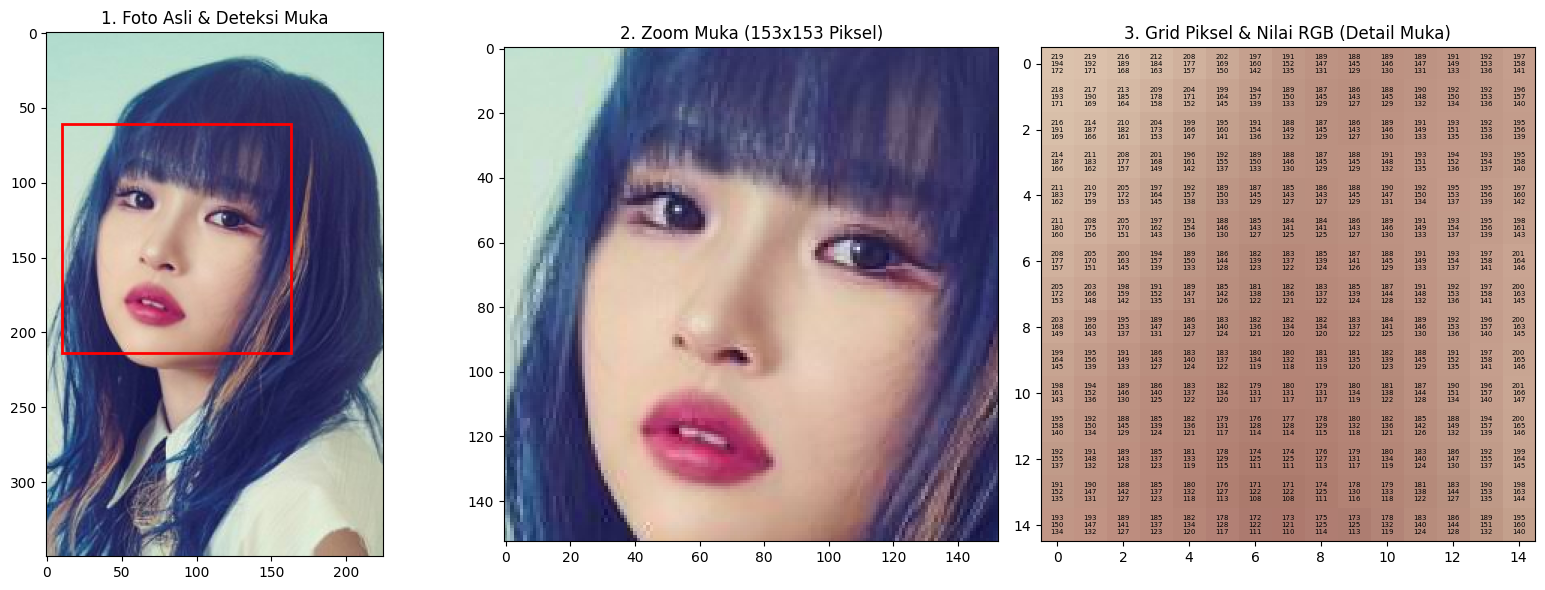

In [1]:
import cv2
import matplotlib.pyplot as plt
import numpy as np

def proses_zoom_muka(path_gambar):
    # 1. Baca gambar menggunakan OpenCV
    img_bgr = cv2.imread(path_gambar)
    if img_bgr is None:
        print(f"Error: Tidak dapat membaca gambar dari '{path_gambar}'. Pastikan nama file dan path-nya benar.")
        return
    
    # Konversi format dari BGR (OpenCV) ke RGB (Matplotlib)
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    h, w, _ = img_rgb.shape

    # 2. Deteksi Muka Otomatis menggunakan Haar Cascade bawaan OpenCV
    face_cascade = cv2.CascadeClassifier(cv2.data.haarcascades + 'haarcascade_frontalface_default.xml')
    gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)
    
    faces = face_cascade.detectMultiScale(gray, scaleFactor=1.1, minNeighbors=5, minSize=(30, 30))
    
    if len(faces) > 0:
        # Ambil koordinat wajah pertama yang terdeteksi (x, y, lebar, tinggi)
        fx, fy, fw, fh = faces[0]
        print(f"Wajah terdeteksi di koordinat: x={fx}, y={fy}, w={fw}, h={fh}")
    else:
        print("Wajah tidak terdeteksi secara otomatis. Menggunakan bagian tengah gambar.")
        # Fallback ke bagian tengah jika wajah tidak ditemukan
        fw, fh = int(w * 0.3), int(h * 0.3)
        fx, fy = (w - fw) // 2, (h - fh) // 2

    # 3. Potong (Crop) area muka untuk zoom
    area_zoom = img_rgb[fy:fy+fh, fx:fx+fw]

    # 4. Visualisasi Menggunakan Matplotlib (3 Panel)
    fig, axes = plt.subplots(1, 3, figsize=(16, 6))

    # Panel 1: Foto Asli dengan Kotak Penanda Muka
    axes[0].imshow(img_rgb)
    axes[0].set_title("1. Foto Asli & Deteksi Muka")
    axes[0].axis("on")
    
    # Tambahkan kotak merah di sekitar wajah
    from matplotlib.patches import Rectangle
    rect = Rectangle((fx, fy), fw, fh, linewidth=2, edgecolor='red', facecolor='none')
    axes[0].add_patch(rect)

    # Panel 2: Hasil Zoom Muka
    axes[1].imshow(area_zoom)
    axes[1].set_title(f"2. Zoom Muka ({fw}x{fh} Piksel)")
    axes[1].axis("on")

    # Panel 3: Grid Piksel & Nilai RGB pada Bagian Muka
    zh, zw, _ = area_zoom.shape
    
    # Batasi ukuran grid maksimal (misal 15x15 piksel di tengah area muka) agar teks nilai RGB terbaca jelas
    max_grid = 15
    if zh > max_grid or zw > max_grid:
        sz_h = min(zh, max_grid)
        sz_w = min(zw, max_grid)
        sy1 = (zh - sz_h) // 2
        sx1 = (zw - sz_w) // 2
        grid_area = area_zoom[sy1:sy1+sz_h, sx1:sx1+sz_w]
    else:
        grid_area = area_zoom

    axes[2].imshow(grid_area, interpolation='nearest')
    axes[2].set_title("3. Grid Piksel & Nilai RGB (Detail Muka)")
    
    gh, gw, _ = grid_area.shape
    for i in range(gh):
        for j in range(gw):
            r, g, b = grid_area[i, j]
            # Tentukan warna teks (putih/hitam) agar kontras dengan warna piksel
            brightness = (int(r) * 299 + int(g) * 587 + int(b) * 114) / 1000
            text_color = "black" if brightness > 128 else "white"
            
            # Format teks nilai RGB bertumpuk ke bawah
            val_text = f"{r}\n{g}\n{b}"
            axes[2].text(j, i, val_text, ha='center', va='center', color=text_color, fontsize=5)

    plt.tight_layout()
    plt.show()

# --- Cara Menjalankan ---
if __name__ == "__main__":
    # Ganti 'foto_anda.jpg' dengan nama file foto Anda yang ada di folder yang sama
    path_file = 'img/images (1).jpg'  # Contoh nama file
    proses_zoom_muka(path_file)

Wajah terdeteksi di koordinat: x=130, y=101, w=137, h=137


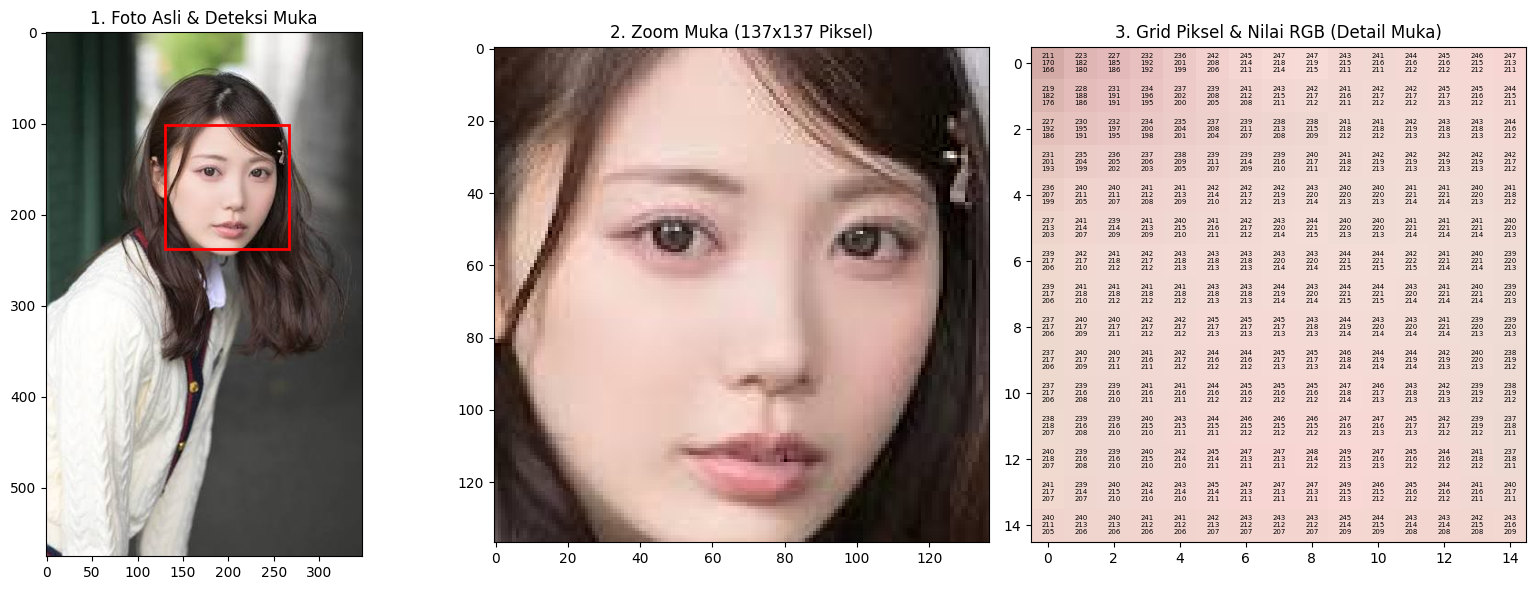

In [2]:
proses_zoom_muka('img/images.jpg')

Menampilkan wajah ke-0 di koordinat: x=125, y=534, w=142, h=142


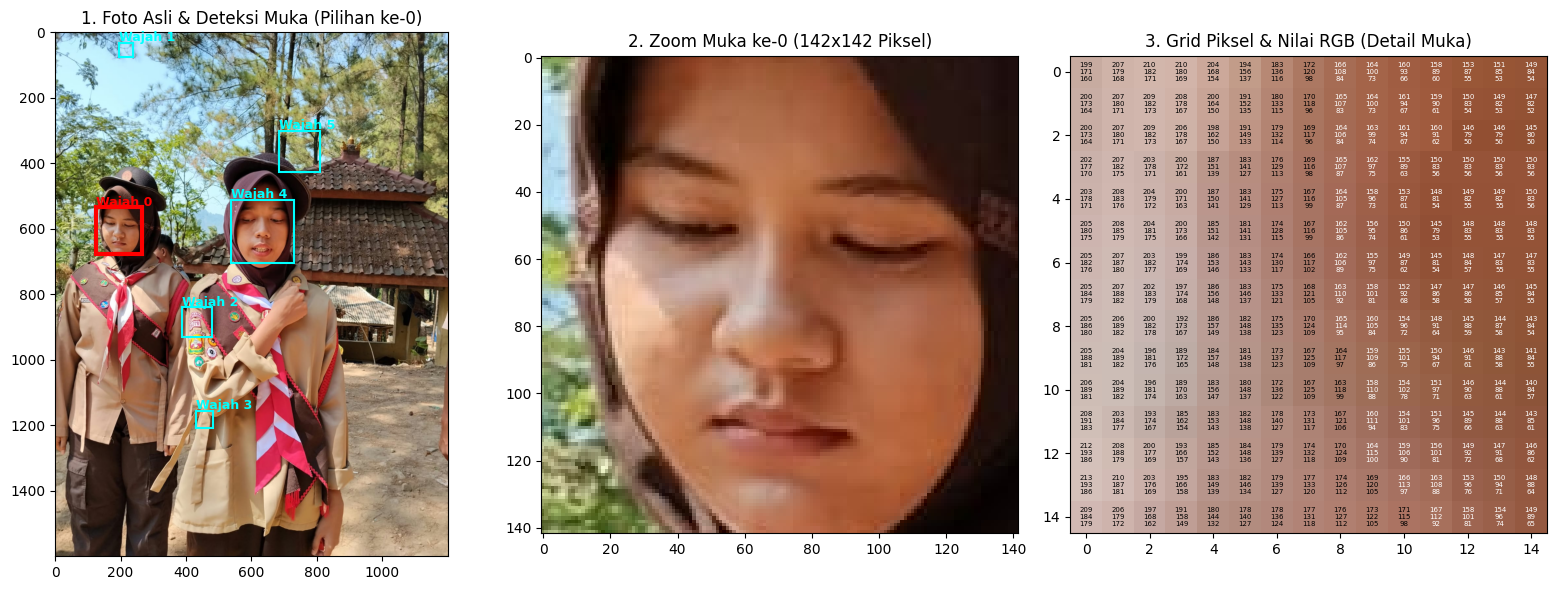

In [3]:
import cv2
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Rectangle

def proses_zoom_muka(path_gambar, index_wajah=0):
    # 1. Baca gambar menggunakan OpenCV
    img_bgr = cv2.imread(path_gambar)
    if img_bgr is None:
        print(f"Error: Tidak dapat membaca gambar dari '{path_gambar}'. Pastikan nama file dan path-nya benar.")
        return
    
    # Konversi format dari BGR (OpenCV) ke RGB (Matplotlib)
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    h, w, _ = img_rgb.shape

    # 2. Deteksi Muka Otomatis menggunakan Haar Cascade bawaan OpenCV
    face_cascade = cv2.CascadeClassifier(cv2.data.haarcascades + 'haarcascade_frontalface_default.xml')
    gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)
    
    # Deteksi semua wajah dalam gambar
    faces = face_cascade.detectMultiScale(gray, scaleFactor=1.1, minNeighbors=5, minSize=(30, 30))
    
    if len(faces) > 0:
        # Urutkan wajah berdasarkan posisi horizontal (dari kiri ke kanan) 
        # atau biarkan sesuai urutan default deteksi OpenCV.
        # Di sini kita urutkan berdasarkan sumbu X (fx) dari kecil ke besar (kiri ke kanan)
        faces = sorted(faces, key=lambda f: f[0])
        
        # Validasi apakah index_wajah yang diminta tersedia
        if index_wajah >= len(faces):
            print(f"Perhatian: Indeks wajah {index_wajah} tidak ditemukan. Hanya ada {len(faces)} wajah terdeteksi.")
            print(f"Otomatis beralih ke wajah indeks 0.")
            index_wajah = 0
            
        fx, fy, fw, fh = faces[index_wajah]
        print(f"Menampilkan wajah ke-{index_wajah} di koordinat: x={fx}, y={fy}, w={fw}, h={fh}")
    else:
        print("Wajah tidak terdeteksi secara otomatis. Menggunakan bagian tengah gambar.")
        fw, fh = int(w * 0.3), int(h * 0.3)
        fx, fy = (w - fw) // 2, (h - fh) // 2

    # 3. Potong (Crop) area muka untuk zoom
    area_zoom = img_rgb[fy:fy+fh, fx:fx+fw]

    # 4. Visualisasi Menggunakan Matplotlib (3 Panel)
    fig, axes = plt.subplots(1, 3, figsize=(16, 6))

    # Panel 1: Foto Asli dengan Kotak Penanda Muka
    axes[0].imshow(img_rgb)
    axes[0].set_title(f"1. Foto Asli & Deteksi Muka (Pilihan ke-{index_wajah})")
    axes[0].axis("on")
    
    # Beri kotak semua wajah dengan warna abu-abu, dan kotak merah untuk wajah yang dipilih
    for idx, (f_x, f_y, f_w, f_h) in enumerate(faces):
        c = 'red' if idx == index_wajah else 'cyan'
        lw = 3 if idx == index_wajah else 1.5
        rect = Rectangle((f_x, f_y), f_w, f_h, linewidth=lw, edgecolor=c, facecolor='none')
        axes[0].add_patch(rect)
        axes[0].text(f_x, f_y - 5, f"Wajah {idx}", color=c, fontsize=9, fontweight='bold')

    # Panel 2: Hasil Zoom Muka
    axes[1].imshow(area_zoom)
    axes[1].set_title(f"2. Zoom Muka ke-{index_wajah} ({fw}x{fh} Piksel)")
    axes[1].axis("on")

    # Panel 3: Grid Piksel & Nilai RGB pada Bagian Muka
    zh, zw, _ = area_zoom.shape
    max_grid = 15
    if zh > max_grid or zw > max_grid:
        sz_h = min(zh, max_grid)
        sz_w = min(zw, max_grid)
        sy1 = (zh - sz_h) // 2
        sx1 = (zw - sz_w) // 2
        grid_area = area_zoom[sy1:sy1+sz_h, sx1:sx1+sz_w]
    else:
        grid_area = area_zoom

    axes[2].imshow(grid_area, interpolation='nearest')
    axes[2].set_title("3. Grid Piksel & Nilai RGB (Detail Muka)")
    
    gh, gw, _ = grid_area.shape
    for i in range(gh):
        for j in range(gw):
            r, g, b = grid_area[i, j]
            brightness = (int(r) * 299 + int(g) * 587 + int(b) * 114) / 1000
            text_color = "black" if brightness > 128 else "white"
            val_text = f"{r}\n{g}\n{b}"
            axes[2].text(j, i, val_text, ha='center', va='center', color=text_color, fontsize=5)

    plt.tight_layout()
    plt.show()

# --- Cara Menjalankan ---
if __name__ == "__main__":
    path_file = 'img/IMG.jpeg'
    
    # Ubah nilai index_wajah sesuai keinginan:
    # 0 = Orang di sebelah kiri (belakang/samping)
    # 1 = Orang di sebelah kanan (depan)
    proses_zoom_muka(path_file, index_wajah=0)

Menampilkan wajah ke-0 di koordinat: x=125, y=534, w=142, h=142


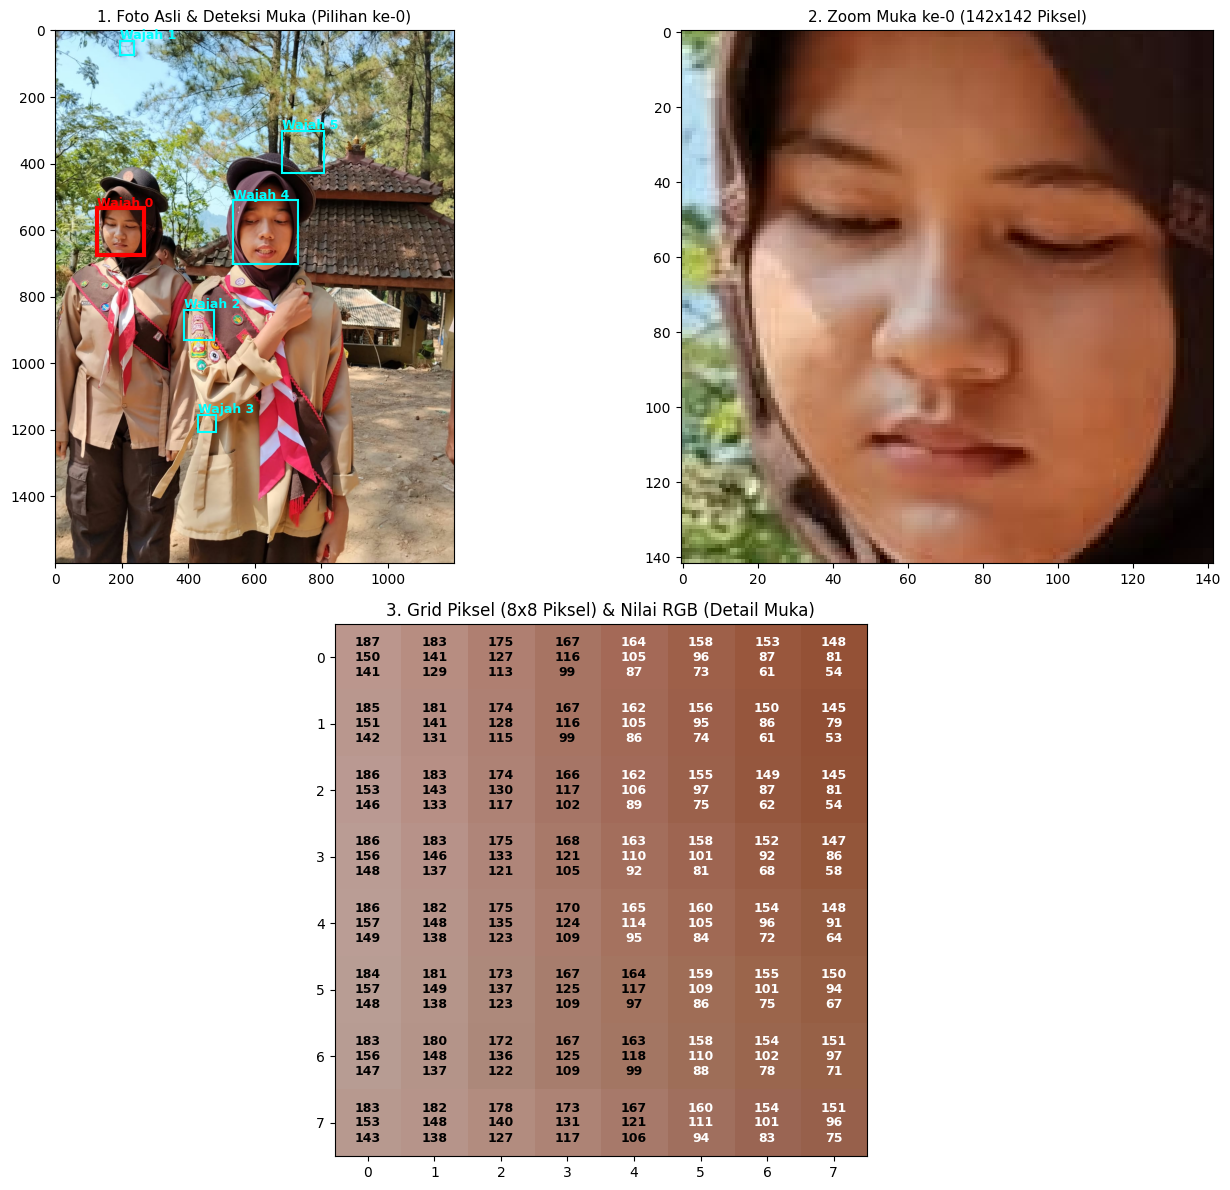

In [4]:
import cv2
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Rectangle

def proses_zoom_muka(path_gambar, index_wajah=0):
    # 1. Baca gambar menggunakan OpenCV
    img_bgr = cv2.imread(path_gambar)
    if img_bgr is None:
        print(f"Error: Tidak dapat membaca gambar dari '{path_gambar}'. Pastikan nama file dan path-nya benar.")
        return
    
    # Konversi format dari BGR (OpenCV) ke RGB (Matplotlib)
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    h, w, _ = img_rgb.shape

    # 2. Deteksi Muka Otomatis menggunakan Haar Cascade bawaan OpenCV
    face_cascade = cv2.CascadeClassifier(cv2.data.haarcascades + 'haarcascade_frontalface_default.xml')
    gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)
    
    # Deteksi semua wajah dalam gambar
    faces = face_cascade.detectMultiScale(gray, scaleFactor=1.1, minNeighbors=5, minSize=(30, 30))
    
    if len(faces) > 0:
        # Urutkan wajah berdasarkan posisi horizontal (dari kiri ke kanan)
        faces = sorted(faces, key=lambda f: f[0])
        
        # Validasi apakah index_wajah yang diminta tersedia
        if index_wajah >= len(faces):
            print(f"Perhatian: Indeks wajah {index_wajah} tidak ditemukan. Hanya ada {len(faces)} wajah terdeteksi.")
            print(f"Otomatis beralih ke wajah indeks 0.")
            index_wajah = 0
            
        fx, fy, fw, fh = faces[index_wajah]
        print(f"Menampilkan wajah ke-{index_wajah} di koordinat: x={fx}, y={fy}, w={fw}, h={fh}")
    else:
        print("Wajah tidak terdeteksi secara otomatis. Menggunakan bagian tengah gambar.")
        fw, fh = int(w * 0.3), int(h * 0.3)
        fx, fy = (w - fw) // 2, (h - fh) // 2

    # 3. Potong (Crop) area muka untuk zoom
    area_zoom = img_rgb[fy:fy+fh, fx:fx+fw]

    # 4. Visualisasi Menggunakan Matplotlib (Layout Khusus: Atas 2 kolom, Bawah 1 kolom penuh)
    fig = plt.figure(figsize=(14, 12))

    # Panel 1 (Atas-Kiri): Foto Asli & Deteksi Muka
    ax1 = plt.subplot2grid((2, 2), (0, 0))
    ax1.imshow(img_rgb)
    ax1.set_title(f"1. Foto Asli & Deteksi Muka (Pilihan ke-{index_wajah})", fontsize=11)
    ax1.axis("on")
    
    for idx, (f_x, f_y, f_w, f_h) in enumerate(faces):
        c = 'red' if idx == index_wajah else 'cyan'
        lw = 3 if idx == index_wajah else 1.5
        rect = Rectangle((f_x, f_y), f_w, f_h, linewidth=lw, edgecolor=c, facecolor='none')
        ax1.add_patch(rect)
        ax1.text(f_x, f_y - 5, f"Wajah {idx}", color=c, fontsize=9, fontweight='bold')

    # Panel 2 (Atas-Kanan): Hasil Zoom Muka
    ax2 = plt.subplot2grid((2, 2), (0, 1))
    ax2.imshow(area_zoom)
    ax2.set_title(f"2. Zoom Muka ke-{index_wajah} ({fw}x{fh} Piksel)", fontsize=11)
    ax2.axis("on")

    # Panel 3 (Bawah - Full Lebar): Grid Piksel & Nilai RGB
    ax3 = plt.subplot2grid((2, 2), (1, 0), colspan=2)
    
    zh, zw, _ = area_zoom.shape
    max_grid = 8  # Dikecilkan agar kotak piksel di baris bawah tampak besar & jelas
    if zh > max_grid or zw > max_grid:
        sz_h = min(zh, max_grid)
        sz_w = min(zw, max_grid)
        sy1 = (zh - sz_h) // 2
        sx1 = (zw - sz_w) // 2
        grid_area = area_zoom[sy1:sy1+sz_h, sx1:sx1+sz_w]
    else:
        grid_area = area_zoom

    ax3.imshow(grid_area, interpolation='nearest')
    ax3.set_title(f"3. Grid Piksel ({sz_w}x{sz_h} Piksel) & Nilai RGB (Detail Muka)", fontsize=12)
    
    gh, gw, _ = grid_area.shape
    for i in range(gh):
        for j in range(gw):
            r, g, b = grid_area[i, j]
            brightness = (int(r) * 299 + int(g) * 587 + int(b) * 114) / 1000
            text_color = "black" if brightness > 128 else "white"
            val_text = f"{r}\n{g}\n{b}"
            ax3.text(j, i, val_text, ha='center', va='center', color=text_color, fontsize=9, fontweight='bold')

    plt.tight_layout()
    plt.show()

# --- Cara Menjalankan ---
if __name__ == "__main__":
    path_file = 'img/IMG.jpeg'
    
    # index_wajah=0 untuk orang di kiri/belakang, index_wajah=1 untuk orang di kanan/depan
    proses_zoom_muka(path_file, index_wajah=0)

Menampilkan wajah ke-4 di koordinat: x=536, y=510, w=193, h=193


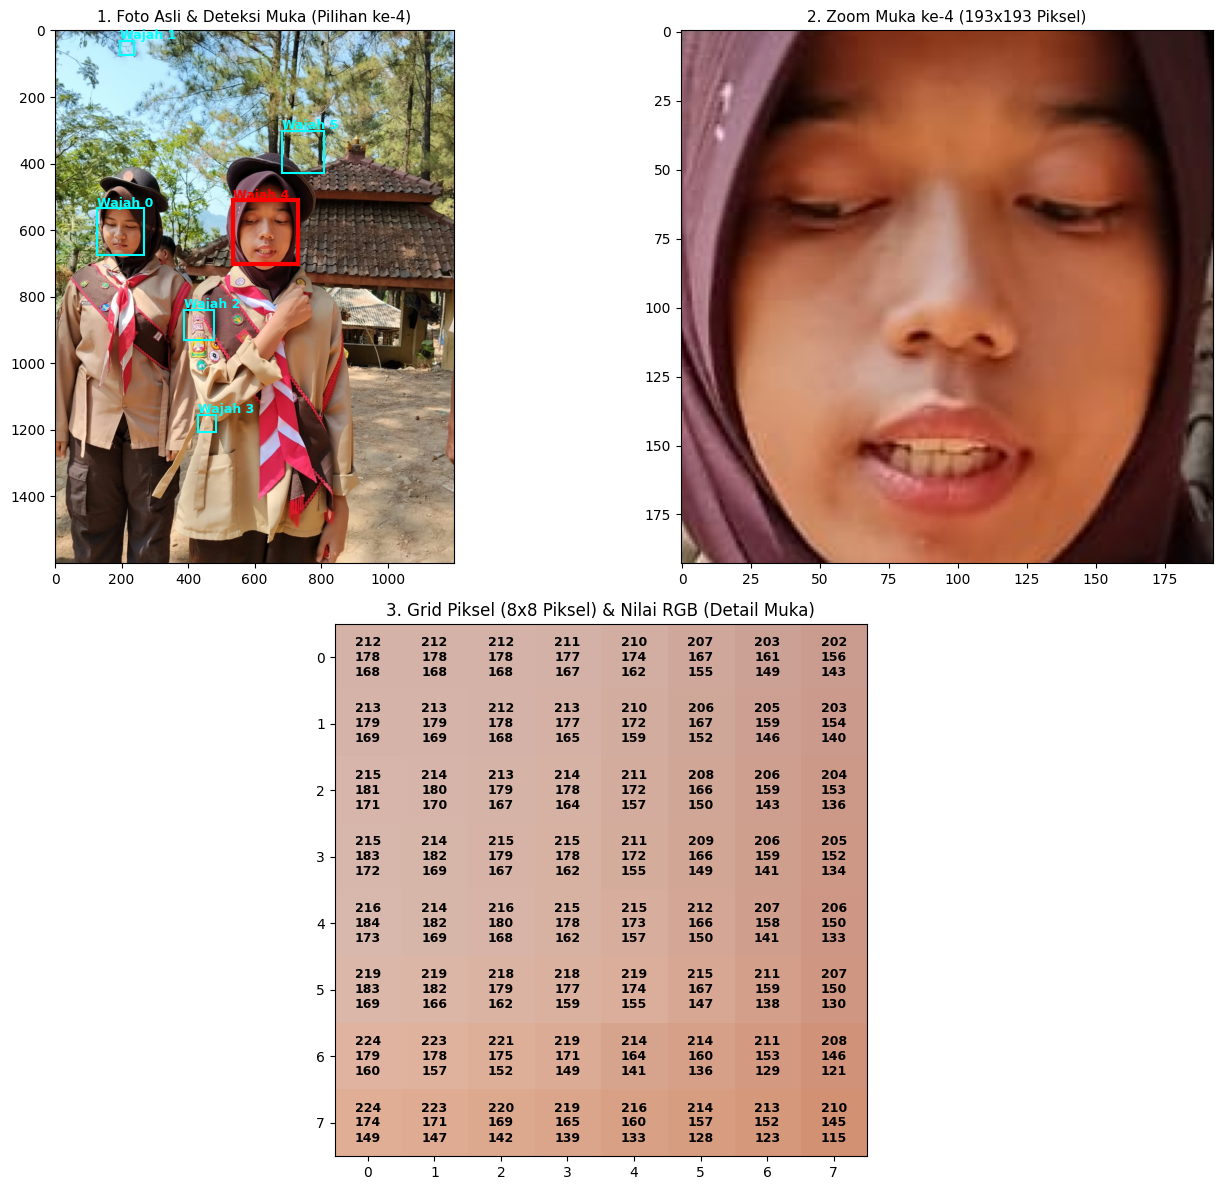

In [5]:
import cv2
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Rectangle

def proses_zoom_muka(path_gambar, index_wajah=0):
    # 1. Baca gambar menggunakan OpenCV
    img_bgr = cv2.imread(path_gambar)
    if img_bgr is None:
        print(f"Error: Tidak dapat membaca gambar dari '{path_gambar}'. Pastikan nama file dan path-nya benar.")
        return
    
    # Konversi format dari BGR (OpenCV) ke RGB (Matplotlib)
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    h, w, _ = img_rgb.shape

    # 2. Deteksi Muka Otomatis menggunakan Haar Cascade bawaan OpenCV
    face_cascade = cv2.CascadeClassifier(cv2.data.haarcascades + 'haarcascade_frontalface_default.xml')
    gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)
    
    # Deteksi semua wajah dalam gambar
    faces = face_cascade.detectMultiScale(gray, scaleFactor=1.1, minNeighbors=5, minSize=(30, 30))
    
    if len(faces) > 0:
        # Urutkan wajah berdasarkan posisi horizontal (dari kiri ke kanan)
        faces = sorted(faces, key=lambda f: f[0])
        
        # Validasi apakah index_wajah yang diminta tersedia
        if index_wajah >= len(faces):
            print(f"Perhatian: Indeks wajah {index_wajah} tidak ditemukan. Hanya ada {len(faces)} wajah terdeteksi.")
            print(f"Otomatis beralih ke wajah indeks 0.")
            index_wajah = 0
            
        fx, fy, fw, fh = faces[index_wajah]
        print(f"Menampilkan wajah ke-{index_wajah} di koordinat: x={fx}, y={fy}, w={fw}, h={fh}")
    else:
        print("Wajah tidak terdeteksi secara otomatis. Menggunakan bagian tengah gambar.")
        fw, fh = int(w * 0.3), int(h * 0.3)
        fx, fy = (w - fw) // 2, (h - fh) // 2

    # 3. Potong (Crop) area muka untuk zoom
    area_zoom = img_rgb[fy:fy+fh, fx:fx+fw]

    # 4. Visualisasi Menggunakan Matplotlib (Layout Khusus: Atas 2 kolom, Bawah 1 kolom penuh)
    fig = plt.figure(figsize=(14, 12))

    # Panel 1 (Atas-Kiri): Foto Asli & Deteksi Muka
    ax1 = plt.subplot2grid((2, 2), (0, 0))
    ax1.imshow(img_rgb)
    ax1.set_title(f"1. Foto Asli & Deteksi Muka (Pilihan ke-{index_wajah})", fontsize=11)
    ax1.axis("on")
    
    for idx, (f_x, f_y, f_w, f_h) in enumerate(faces):
        c = 'red' if idx == index_wajah else 'cyan'
        lw = 3 if idx == index_wajah else 1.5
        rect = Rectangle((f_x, f_y), f_w, f_h, linewidth=lw, edgecolor=c, facecolor='none')
        ax1.add_patch(rect)
        ax1.text(f_x, f_y - 5, f"Wajah {idx}", color=c, fontsize=9, fontweight='bold')

    # Panel 2 (Atas-Kanan): Hasil Zoom Muka
    ax2 = plt.subplot2grid((2, 2), (0, 1))
    ax2.imshow(area_zoom)
    ax2.set_title(f"2. Zoom Muka ke-{index_wajah} ({fw}x{fh} Piksel)", fontsize=11)
    ax2.axis("on")

    # Panel 3 (Bawah - Full Lebar): Grid Piksel & Nilai RGB
    ax3 = plt.subplot2grid((2, 2), (1, 0), colspan=2)
    
    zh, zw, _ = area_zoom.shape
    max_grid = 8  # Dikecilkan agar kotak piksel di baris bawah tampak besar & jelas
    if zh > max_grid or zw > max_grid:
        sz_h = min(zh, max_grid)
        sz_w = min(zw, max_grid)
        sy1 = (zh - sz_h) // 2
        sx1 = (zw - sz_w) // 2
        grid_area = area_zoom[sy1:sy1+sz_h, sx1:sx1+sz_w]
    else:
        grid_area = area_zoom

    ax3.imshow(grid_area, interpolation='nearest')
    ax3.set_title(f"3. Grid Piksel ({sz_w}x{sz_h} Piksel) & Nilai RGB (Detail Muka)", fontsize=12)
    
    gh, gw, _ = grid_area.shape
    for i in range(gh):
        for j in range(gw):
            r, g, b = grid_area[i, j]
            brightness = (int(r) * 299 + int(g) * 587 + int(b) * 114) / 1000
            text_color = "black" if brightness > 128 else "white"
            val_text = f"{r}\n{g}\n{b}"
            ax3.text(j, i, val_text, ha='center', va='center', color=text_color, fontsize=9, fontweight='bold')

    plt.tight_layout()
    plt.show()

# --- Cara Menjalankan ---
if __name__ == "__main__":
    path_file = 'img/IMG.jpeg'
    
    # index_wajah=0 untuk orang di kiri/belakang, index_wajah=1 untuk orang di kanan/depan
    proses_zoom_muka(path_file, index_wajah=4)